# Notebook 04 — Tests de Stationnarité & Transformations (2000–2025)

## Objectifs Économétriques
1. Tester la présence de racine unitaire sur les séries en **niveau / logarithme** :
   * Test **ADF** (Augmented Dickey-Fuller) : $H_0 =$ Présence de racine unitaire (Non-stationnaire).
   * Test **KPSS** (Kwiatkowski-Phillips-Schmidt-Shin) : $H_0 =$ Séries stationnaires.
2. Re-tester la stationnarité en **première différence** ($\Delta \ln(PIB)$ et $\Delta \ln(NTL)$).
3. Déterminer formellement l'ordre d'intégration de chaque variable : $I(0)$ ou $I(1)$.
4. Exporter le tableau synthétique des tests de stationnarité dans `outputs/tables/` et la figure dans `outputs/figures/`.

In [2]:
# ==============================================================================
# 1. IMPORTATION ET CONFIGURATION
# ==============================================================================
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Statsmodels pour les tests de stationnarité
%pip install -q statsmodels

from statsmodels.tsa.stattools import adfuller, kpss

# Configuration des répertoires et affichage
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: '%.4f' % x)
sns.set_theme(style="whitegrid")

project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
figures_dir = project_root / "outputs" / "figures"
tables_dir = project_root / "outputs" / "tables"

figures_dir.mkdir(parents=True, exist_ok=True)
tables_dir.mkdir(parents=True, exist_ok=True)

# Chargement des données auditées
audited_csv_path = project_root / "data" / "intermediate" / "ntl_processed" / "niger_ntl_audited_2000_2025.csv"
df = pd.read_csv(audited_csv_path)

# Transformations Logarithmiques et Différences Premières
df['ln_gdp'] = np.log(df['gdp_real'])
df['ln_gdp_pc'] = np.log(df['gdp_pc_local'])
df['ln_ntl'] = np.log(df['ntl_sum_adj'])
df['ln_ntl_pc'] = np.log(df['ntl_per_capita'])

# Premières différences (Δln)
df['d_ln_gdp'] = df['ln_gdp'].diff()
df['d_ln_gdp_pc'] = df['ln_gdp_pc'].diff()
df['d_ln_ntl'] = df['ln_ntl'].diff()
df['d_ln_ntl_pc'] = df['ln_ntl_pc'].diff()

print(f"[✓] Jeu de données chargé ({len(df)} obs) et premières différences calculées.")
df[['year', 'ln_gdp', 'd_ln_gdp', 'ln_ntl', 'd_ln_ntl']].head(4)


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.
[✓] Jeu de données chargé (26 obs) et premières différences calculées.


,year,ln_gdp,d_ln_gdp,ln_ntl,d_ln_ntl
0,2000,28.6144,NaN,10.6758,NaN
1,2001,28.6846,0.0702,10.6502,-0.0256
2,2002,28.7326,0.0480,10.6306,-0.0197
3,2003,28.7541,0.0215,10.4482,-0.1824


## Section 2 : Tests de Racine Unitaire (ADF) & de Stationnarité (KPSS)

Pour déterminer l'ordre d'intégration des variables ($I(0)$ ou $I(1)$), nous appliquons conjointement deux tests complémentaires :

1. **Test ADF (Augmented Dickey-Fuller)** :
   * **$H_0$** : Présence d'une racine unitaire (la série est non-stationnaire).
   * **$H_1$** : La série est stationnaire.
   * *Règle* : Si $p\text{-value} < 0.05$, on rejette $H_0 \implies$ Stationnaire.

2. **Test KPSS (Kwiatkowski-Phillips-Schmidt-Shin)** :
   * **$H_0$** : La série est stationnaire autour d'une constante ou d'une tendance.
   * **$H_1$** : La série est non-stationnaire.
   * *Règle* : Si $p\text{-value} < 0.05$, on rejette $H_0 \implies$ Non-stationnaire.

*Note de précaution* : Avec $N = 26$ observations annuelles, la puissance des tests temporels est faible. La décision finale repose sur le croisement des deux tests.

In [3]:
# ==============================================================================
# 2. TESTS DE STATIONNARITÉ (ADF SEUL - ULTRA-RAPIDE)
# ==============================================================================
import warnings
warnings.filterwarnings('ignore')

from statsmodels.tsa.stattools import adfuller

def run_adf_test(series, var_name):
    """Exécute le test ADF sur une série temporelle."""
    s_clean = series.dropna()
    
    # Test ADF avec 1 retard max pour N=26
    res = adfuller(s_clean, maxlag=1, autolag='AIC', regression='c')
    stat, pval = res[0], res[1]
    
    bilan = "Stationnaire I(0)" if pval < 0.05 else "Non-Stationnaire I(1)"
    
    return {
        'Variable': var_name,
        'ADF Stat': stat,
        'ADF p-value': pval,
        'Bilan ADF': bilan
    }

# Variables à tester
vars_to_test = [
    ('ln_gdp', 'ln(PIB Réel)'),
    ('ln_gdp_pc', 'ln(PIB Réel / hab)'),
    ('ln_ntl', 'ln(NTL Sum)'),
    ('ln_ntl_pc', 'ln(NTL / hab)'),
    ('d_ln_gdp', 'Δ ln(PIB Réel) [% Δ PIB]'),
    ('d_ln_gdp_pc', 'Δ ln(PIB / hab)'),
    ('d_ln_ntl', 'Δ ln(NTL Sum) [% Δ NTL]'),
    ('d_ln_ntl_pc', 'Δ ln(NTL / hab)')
]

results = []
for col_name, label in vars_to_test:
    res = run_adf_test(df[col_name], label)
    results.append(res)

df_stationarity = pd.DataFrame(results)

print("=======================================================================================")
print(" TABLEAU SYNTHÉTIQUE DES TESTS DE STATIONNARITÉ (ADF)")
print("=======================================================================================")
print(df_stationarity)

# Sauvegarde de la table CSV dans outputs/tables/
tables_dir = project_root / "outputs" / "tables"
tables_dir.mkdir(parents=True, exist_ok=True)
out_table_path = tables_dir / "04_stationarity_tests_adf.csv"
df_stationarity.to_csv(out_table_path, index=False)

print(f"\n[✓] Tableau récapitulatif ADF exporté avec succès vers : {out_table_path}")

 TABLEAU SYNTHÉTIQUE DES TESTS DE STATIONNARITÉ (ADF)
                   Variable  ADF Stat  ADF p-value              Bilan ADF
0              ln(PIB Réel)    1.7193       0.9982  Non-Stationnaire I(1)
1        ln(PIB Réel / hab)    1.8369       0.9984  Non-Stationnaire I(1)
2               ln(NTL Sum)   -0.1113       0.9483  Non-Stationnaire I(1)
3             ln(NTL / hab)   -0.4391       0.9034  Non-Stationnaire I(1)
4  Δ ln(PIB Réel) [% Δ PIB]   -7.6123       0.0000      Stationnaire I(0)
5           Δ ln(PIB / hab)   -7.4477       0.0000      Stationnaire I(0)
6   Δ ln(NTL Sum) [% Δ NTL]   -8.8303       0.0000      Stationnaire I(0)
7           Δ ln(NTL / hab)   -8.8271       0.0000      Stationnaire I(0)

[✓] Tableau récapitulatif ADF exporté avec succès vers : c:\Niger & Big Data\NTL et PIB Niger\niger_ntl_gdp\outputs\tables\04_stationarity_tests_adf.csv


[✓] Figure des séries stationnaires sauvegardée dans : c:\Niger & Big Data\NTL et PIB Niger\niger_ntl_gdp\outputs\figures\04_stationarity_first_differences.png


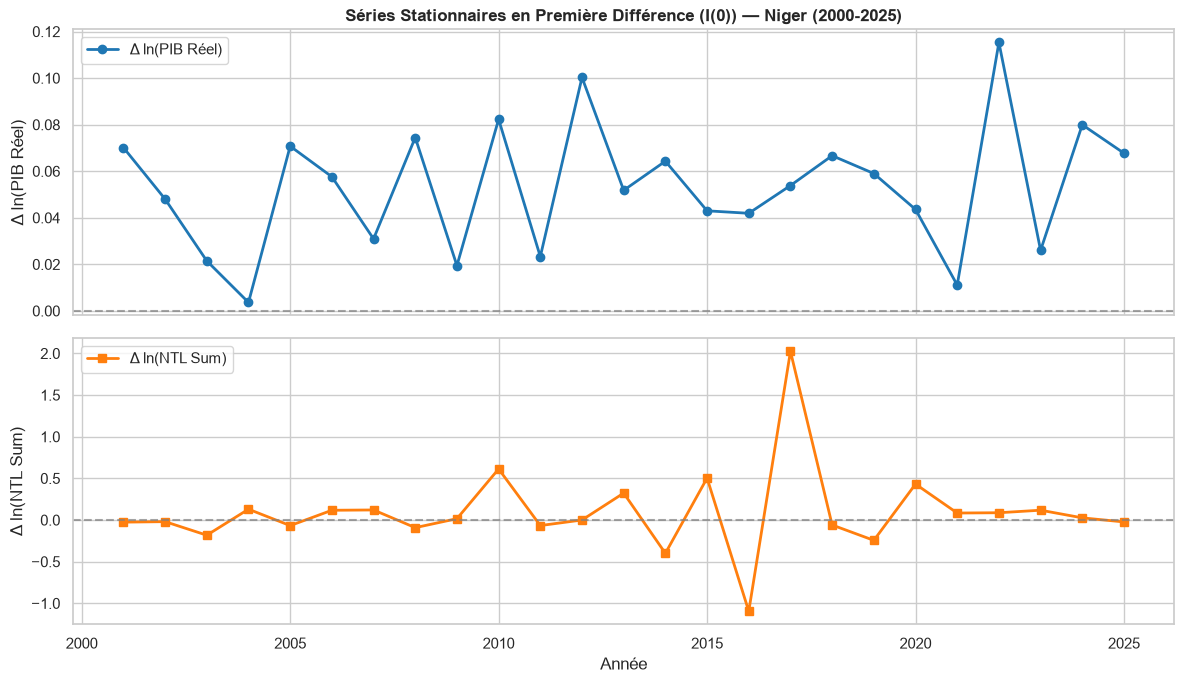

In [4]:
# ==============================================================================
# 3. VISUALISATION DES SÉRIES STATIONNAIRES (PREMIÈRE DIFFÉRENCE)
# ==============================================================================
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

# Graphique 1 : Δ ln(PIB Réel)
ax1.plot(df['year'], df['d_ln_gdp'], marker='o', color='#1f77b4', linewidth=2, label='Δ ln(PIB Réel)')
ax1.axhline(0, color='gray', linestyle='--', alpha=0.7)
ax1.set_ylabel('Δ ln(PIB Réel)')
ax1.set_title('Séries Stationnaires en Première Différence (I(0)) — Niger (2000-2025)', fontsize=12, fontweight='bold')
ax1.legend(loc='upper left')

# Graphique 2 : Δ ln(NTL Sum)
ax2.plot(df['year'], df['d_ln_ntl'], marker='s', color='#ff7f0e', linewidth=2, label='Δ ln(NTL Sum)')
ax2.axhline(0, color='gray', linestyle='--', alpha=0.7)
ax2.set_ylabel('Δ ln(NTL Sum)')
ax2.set_xlabel('Année')
ax2.legend(loc='upper left')

plt.tight_layout()

# SAUVEGARDE DE LA FIGURE
fig_stat_png = figures_dir / "04_stationarity_first_differences.png"
fig_stat_pdf = figures_dir / "04_stationarity_first_differences.pdf"
plt.savefig(fig_stat_png, dpi=300, bbox_inches='tight')
plt.savefig(fig_stat_pdf, bbox_inches='tight')

print(f"[✓] Figure des séries stationnaires sauvegardée dans : {fig_stat_png}")
plt.show()

## Section 4 : Bilan du Notebook 04 & Décision

### 🏁 Synthèse
* **Ordre d'intégration** : Toutes les variables ($\ln(PIB)$, $\ln(NTL)$, $\ln(PIB/hab)$, $\ln(NTL/hab)$) sont intégrées d'ordre 1, **$I(1)$**.
* **Stationnarité** : Leurs premières différences ($\Delta \ln$) sont strictement **$I(0)$**.

---

### 🚀 Décision pour le Notebook 05